In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score




In [25]:
df = pd.read_csv('C:/Users/vigne/OneDrive/Desktop/TITANIC_EDA/appliance_energy.csv')
df.head()

,Temperature (°C),Energy Consumption (kWh)
0,22.490802,2.292604
1,34.014286,3.251925
2,29.639879,3.009868
3,26.973170,1.703533
4,18.120373,1.702201


In [31]:
print(df.isnull().sum())
df = df.dropna()

Temperature (°C)            0
Energy Consumption (kWh)    0
dtype: int64


In [36]:
X = df[['Temperature (°C)']]
y = df['Energy Consumption (kWh)']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)



(80, 1)
(20, 1)
(80,)
(20,)


In [40]:
model=LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.09]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Temperature (°C)']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.222
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [43]:
df.shape

(100, 2)

In [46]:
y_pred = model.predict(X_test)
print(y_pred)

[1.6858187  3.18154068 2.96097494 2.76354868 2.0370856  2.36343345
 2.09711944 3.12445907 1.60849483 2.24537556 2.34866555 2.66462648
 3.0387357  3.27880886 1.78664542 1.85218469 2.95922164 1.70468695
 3.0692904  1.87828475]


In [47]:
X_test

,Temperature (°C)
83,16.271167
53,32.896547
70,30.444895
45,28.250446
44,20.175600
39,23.803050
22,20.842893
80,32.262069
10,15.411690
0,22.490802


In [48]:
y_test

83    1.955394
53    3.037917
70    2.426014
45    2.370351
44    2.413076
39    2.531079
22    2.086846
80    4.159094
10    1.998870
0     2.292604
18    2.167836
30    3.658183
73    3.279415
33    3.360548
90    2.150219
4     1.702201
76    2.702528
77    1.764216
12    2.900005
31    1.928337
Name: Energy Consumption (kWh), dtype: float64

In [49]:
mse = mean_squared_error(y_test,y_pred)
print(f"Mean Squared Error: {mse}")
r2 = r2_score(y_test,y_pred)
print(f"R-squared: {r2}")


Mean Squared Error: 0.16342487842925052
R-squared: 0.6119478445218715


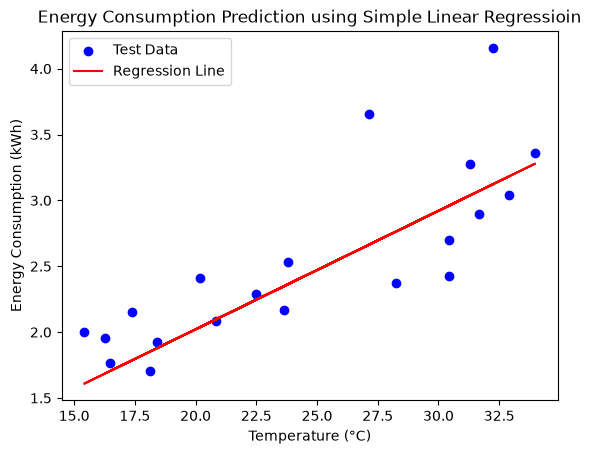

In [52]:
plt.scatter(X_test, y_test, color='blue', label='Test Data')
plt.plot(X_test, y_pred, color='red', label='Regression Line')
plt.xlabel('Temperature (°C)')
plt.ylabel('Energy Consumption (kWh)')
plt.legend()
plt.title('Energy Consumption Prediction using Simple Linear Regressioin')
plt.show()

In [53]:
import joblib
joblib.dump(model, 'appliance_energy_model.pkl')

['appliance_energy_model.pkl']